# ASTR 5820 Problem Set 2

## 1. Build the Module

github repo: https://github.com/rhaliattar/astr5820.git

The Calculated Hill Radius of Earth is 1.5e+09 m = 1.0e-02 AU, which has a 2.3e-01% error from the true value.
The Calculated Hill Radius of Earth is 6.4e+01 kg/m^3, which has a 3.6e-01% error from the true value.


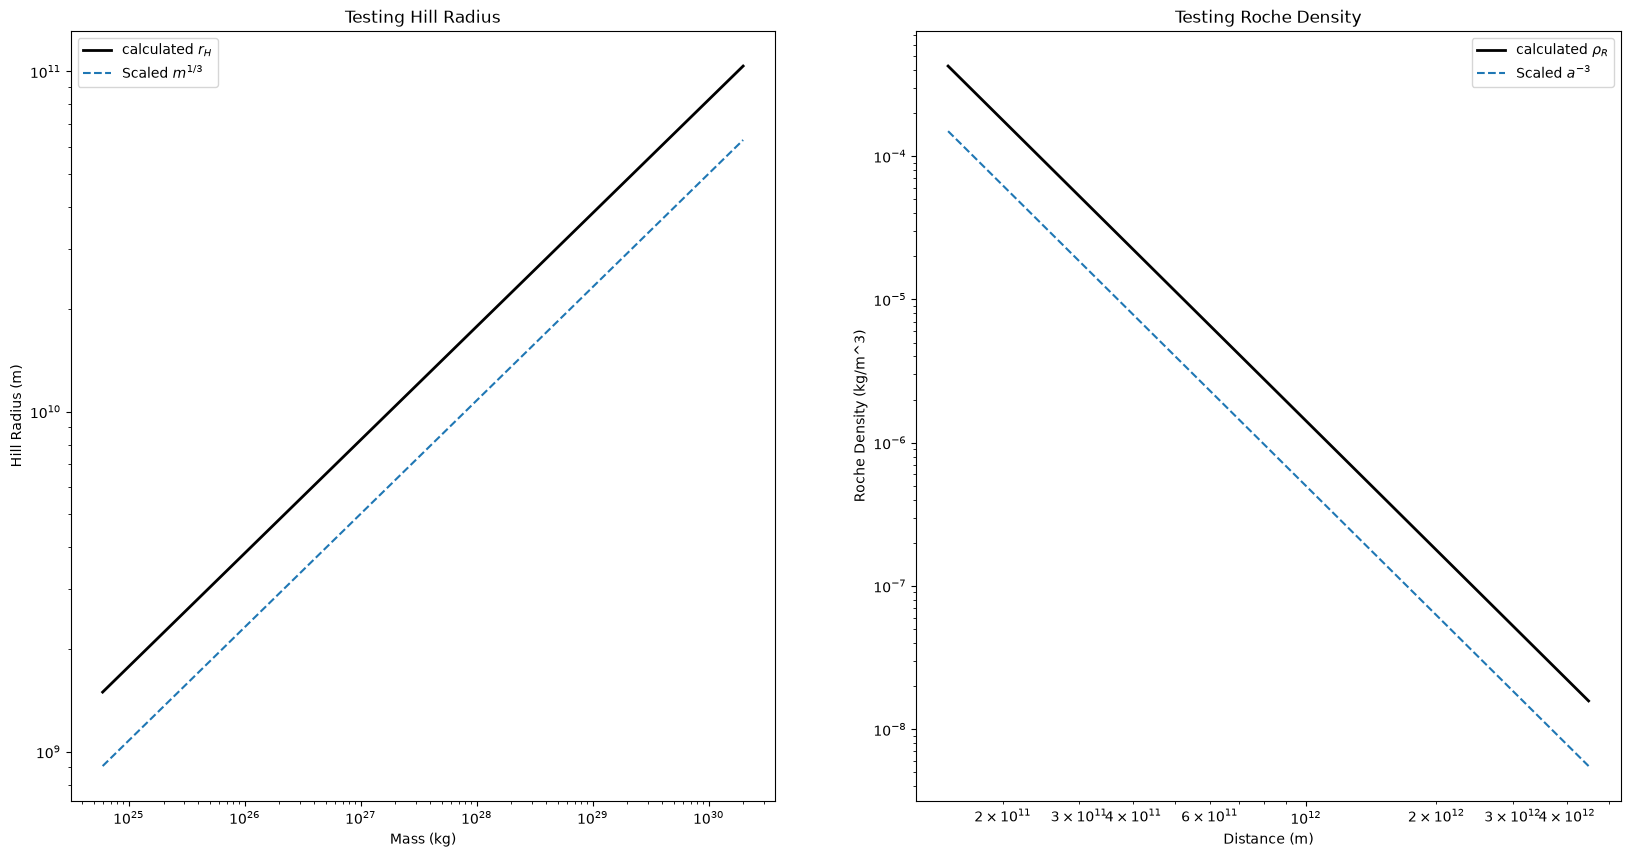

In [1]:
from astrotools.nbody import twobody, integrators
from astrotools.constants import M_EARTH, M_SUN, AU, G
import matplotlib.pyplot as plt
import numpy as np

earth_r_H = 1.5*1e9
calculated_r_H = twobody.hill_radius(AU, M_EARTH)
print('The Calculated Hill Radius of Earth is {:.1e} m = {:.1e} AU, which has a {:.1e}% error from the true value.'.format(calculated_r_H, calculated_r_H/AU, 100-calculated_r_H/earth_r_H * 100))

roche_at_mimas = 64
calculated_roche = twobody.roche_density(1.855*1e8, m_star=5.6834*1e26)
print('The Calculated Hill Radius of Earth is {:.1e} kg/m^3, which has a {:.1e}% error from the true value.'.format(calculated_roche, 100 - 100 * calculated_roche/roche_at_mimas))

all_masses = np.linspace(M_EARTH, M_SUN, 1000)
all_distances = np.linspace(AU, 30*AU, 1000)

fig, ax = plt.subplots(1, 2, figsize = (20, 10))

ax[0].loglog(all_masses, twobody.hill_radius(AU, all_masses), color = 'black', linewidth = 2, label = r'calculated $r_H$')
ax[0].loglog(all_masses, 5*all_masses**(1/3), '--', label = r'Scaled $m^{1/3}$')

ax[1].loglog(all_distances, twobody.roche_density(all_distances), color = 'black', linewidth = 2, label = r'calculated $\rho_R$')
ax[1].loglog(all_distances, 5e29*all_distances**(-3), '--', label = r'Scaled $a^{-3}$')

ax[0].set_title("Testing Hill Radius")
ax[0].set_xlabel('Mass (kg)')
ax[0].set_ylabel('Hill Radius (m)')
ax[0].legend()

ax[1].set_title('Testing Roche Density')
ax[1].set_xlabel('Distance (m)')
ax[1].set_ylabel('Roche Density (kg/m^3)')
ax[1].legend()

In [2]:
big_step_size = integrators.integrate(integrators.rk4_step, twobody.kepler_derivs, twobody.initial_conditions(AU, e=0), (0, twobody.orbital_period(AU)), twobody.orbital_period(AU)/100)
big_x, big_y, _, _ = big_step_size[1].T
half_step_size = integrators.integrate(integrators.rk4_step, twobody.kepler_derivs, twobody.initial_conditions(AU, e=0), (0, twobody.orbital_period(AU)), twobody.orbital_period(AU)/200)
half_x, half_y, _, _ = half_step_size[1].T

big_distance = np.sqrt(big_x **2 + big_y **2)
half_distance = np.sqrt(half_x **2 + half_y **2)
position_error_big = (big_distance[0]-big_distance[-1])/big_distance[0]
position_error_half = (half_distance[0]-half_distance[-1])/half_distance[0]
print("I'm unsure why but the position error decreased by a factor of ~{}.".format(round(position_error_big/position_error_half)))

I'm unsure why but the position error decreased by a factor of ~32.


## 2. The reference orbit

### Part (a)

In [3]:
# vis-viva
rp = AU*(1-0.3)
ra = AU*(1+0.3)
vp = np.sqrt(G*M_SUN*(2/rp - 1/AU))
va = np.sqrt(G*M_SUN*(2/ra - 1/AU))

# kepler's third law
P = np.sqrt(4 * np.pi**2 * AU**3/(G * (M_EARTH + M_SUN)))

E = -G*M_SUN/(2*AU)
j = np.sqrt(G*M_SUN*AU*(1-0.3**2))

print('P = {:.2e} s'.format(P))
print('v_p = {:.2e} m/s'.format(vp))
print('v_a = {:.2e} m/s'.format(va))
print('j = {:.2e} m^2/s'.format(j))
print('E = {:.2e} J'.format(E))
print('r_p*v_p/r_a*v_a = {}'.format(rp*vp/(ra*va)))
print('r_p*v_p/j = {}'.format(rp*vp/j, ra*va/j))
print('r_a*v_a/j = {}'.format(ra*va/j))

P = 3.16e+07 s
v_p = 4.06e+04 m/s
v_a = 2.19e+04 m/s
j = 4.25e+15 m^2/s
E = -4.44e+08 J
r_p*v_p/r_a*v_a = 1.0
r_p*v_p/j = 1.0
r_a*v_a/j = 1.0


### Part (b)

In [4]:
full_orbit = integrators.integrate(integrators.rk4_step, twobody.kepler_derivs, twobody.initial_conditions(AU, e=0.3), (0, P), P/1000)
specific_energy = twobody.specific_energy(full_orbit[1])
position = np.sqrt(full_orbit[1].T[0]**2 + full_orbit[1].T[1]**2)

print('Fractional Error in Specific Energy = {:.2e}.'.format((specific_energy[0]-specific_energy[-1])/specific_energy[0]))
print('Fractional Error in Position = {:.2e}.'.format((position[0]-position[-1])/position[0]))

Fractional Error in Specific Energy = -1.55e-11.
Fractional Error in Position = -3.85e-11.


### Part (c)

Arranged in increasing order of specific angular momentum, we have the solar break up value of $3 \times 10^{14}$ $m^2/s$, then this orbit with $4.25 \times 10^{15}$ $m^2/s$, and lastly the fiducial core with $6.3 \times 10^{15}$ $m^2/s$. So, when the core collapsed into the Sun, most of the angular momentum was transfered to the orbits of the planets of the solar system and very little was left over for the sun.

## 3. How long can an orbit calculation be trusted?

### Part (a)

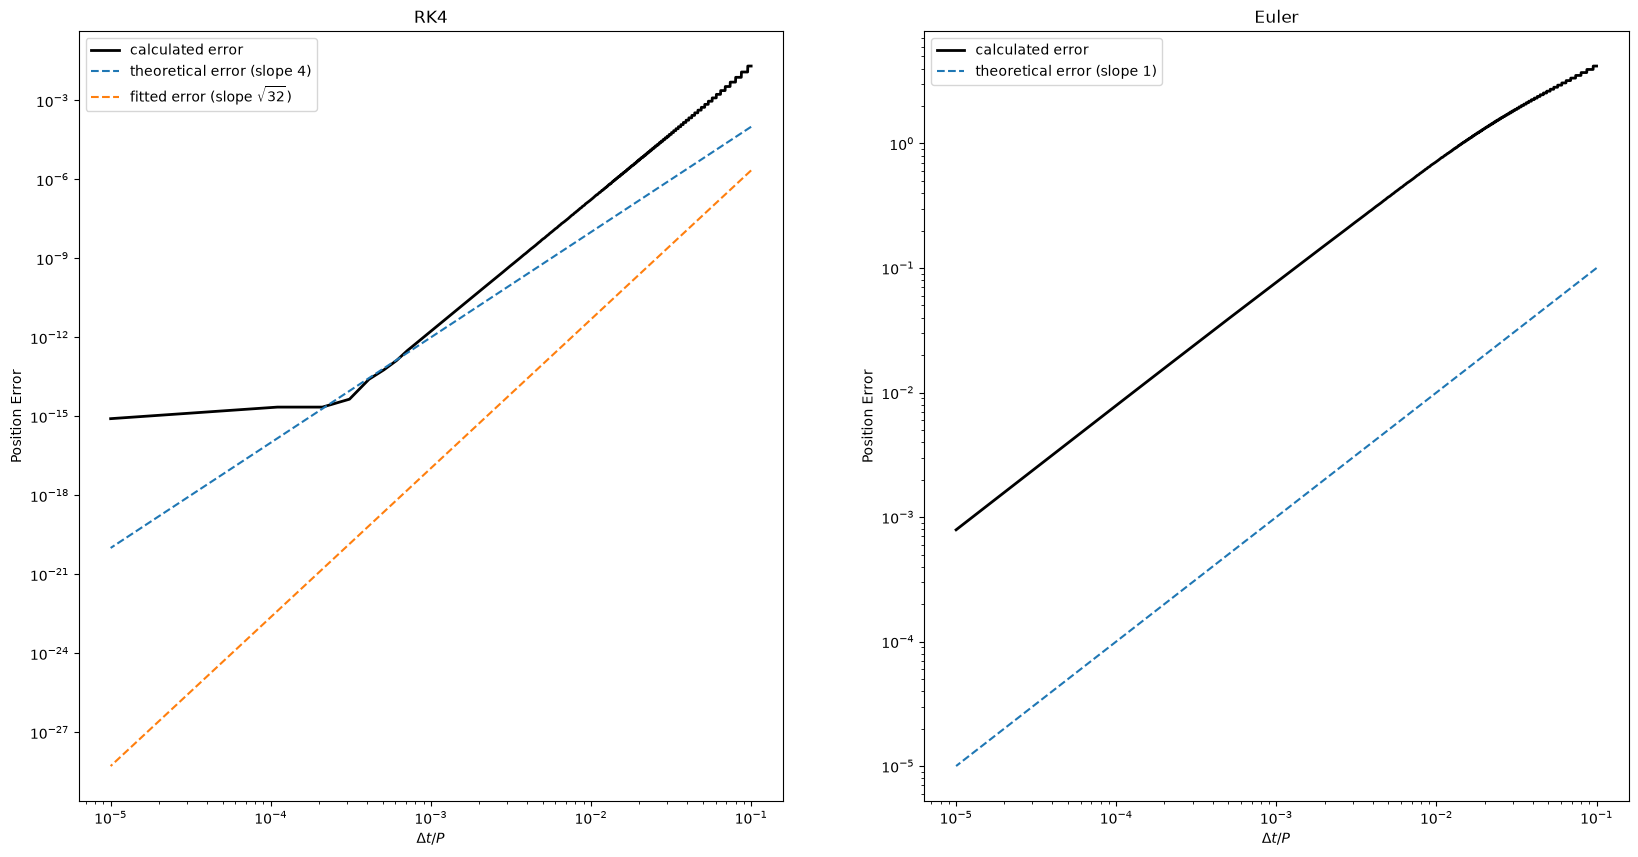

In [ ]:
P = twobody.orbital_period(AU)

'''
I'm not quite sure what we mean by asymptotic regime, but I'm assuming this is like saying the timestep is small enough that we get to an equilibrium by the end of the orbit?
I checked this by plotting the results with the smallest dt I have chosen and a full orbit was completed. 
'''

rk4_steps = np.linspace(P/10, P/1e5, 1000)
rk4_error = []
euler_steps = np.linspace(P/10, P/1e5, 1000)
euler_error = []

for i in range(1000):
    full_orbit_rk4 = integrators.integrate(integrators.rk4_step, twobody.kepler_derivs, twobody.initial_conditions(AU, e=0), (0, P), rk4_steps[i])
    position_rk4 = np.sqrt(full_orbit_rk4[1].T[0]**2 + full_orbit_rk4[1].T[1]**2)
    rk4_error.append(np.abs(position_rk4[0]-position_rk4[-1])/position_rk4[0])

    full_orbit_euler = integrators.integrate(integrators.euler_step, twobody.kepler_derivs, twobody.initial_conditions(AU, e=0), (0, P), euler_steps[i])
    position_euler = np.sqrt(full_orbit_euler[1].T[0]**2 + full_orbit_euler[1].T[1]**2)
    euler_error.append(np.abs(position_euler[0]-position_euler[-1])/position_euler[0])

fig, ax = plt.subplots(1, 2, figsize = (20, 10))

ax[0].loglog(rk4_steps/P, rk4_error, color = 'black', linewidth = 2, label = r'calculated error')
ax[0].loglog(rk4_steps/P, (rk4_steps/P)**4, '--', label = r'theoretical error (slope 4)')
ax[0].loglog(rk4_steps/P, (rk4_steps/P)**np.sqrt(32), '--', label = r'fitted error (slope $\sqrt{32}$)')

ax[1].loglog(euler_steps/P, euler_error, color = 'black', linewidth = 2, label = r'calculated error')
ax[1].loglog(euler_steps/P, euler_steps/P, '--', label = r'theoretical error (slope 1)')

ax[0].set_ylabel('Position Error')
ax[0].set_xlabel(r'$\Delta t/P$')
ax[0].set_title('RK4')
ax[0].legend()

ax[1].set_ylabel('Position Error')
ax[1].set_xlabel(r'$\Delta t/P$')
ax[1].set_title('Euler')
ax[1].legend()

For the Euler method, the theoretical slope of 1 matches the error but for the RK4 method, I'm getting that a slope of $\sqrt{32}$ matches better than the theoretical slope of 4. This matches the strange result that I got in Problem 1, and I'm not sure why I'm getting this improvement. 

Moreover, the error stops falling once it reaches around $10^{-15}$ which is right around the double-precision floating point round-off where numbers become to small for the double-precision representation to work, so they just get rounded up. Therefore, this is an issue with the computer's limit for processing small numbers and not an issue with the RK4 method.

### Part (b)

The energy drift per orbit is 5.4693843618313956e-11 for RK4.


Text(0.5, 1.0, 'Euler')

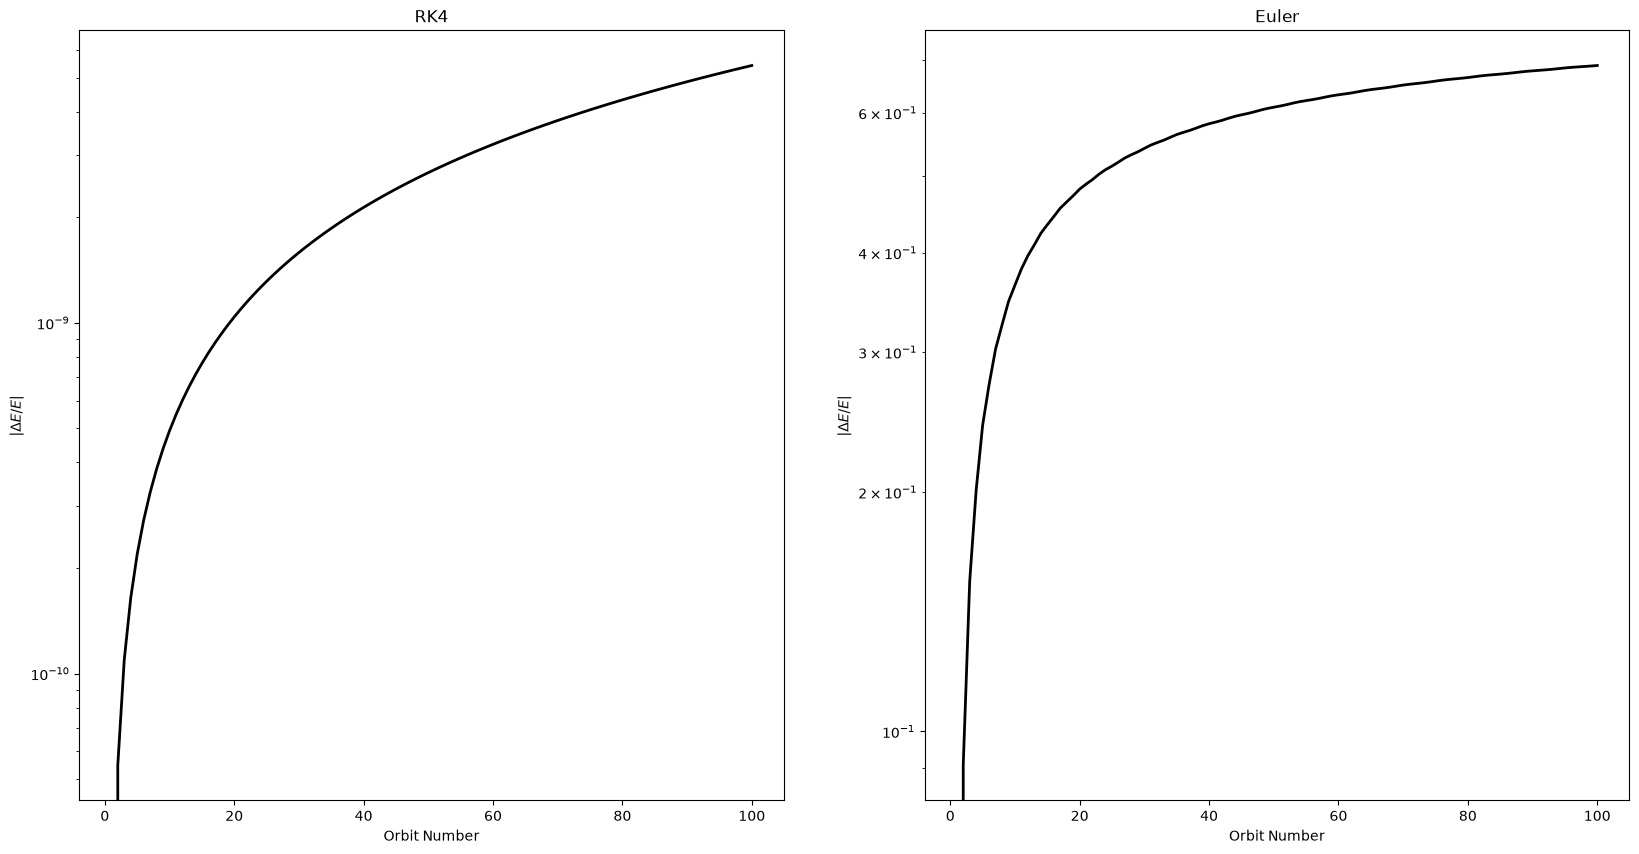

In [16]:
orbit_number = np.linspace(1, 100, 100, dtype = int)
position_error_rk4 = []
orbit_number_euler = []
position_error_euler = []

orbits_rk4 = integrators.integrate(integrators.rk4_step, twobody.kepler_derivs, twobody.initial_conditions(AU, e=0), (0, 100*P), P/500)
energy_rk4 = twobody.specific_energy(orbits_rk4[1][500*orbit_number])
orbits_euler = integrators.integrate(integrators.euler_step, twobody.kepler_derivs, twobody.initial_conditions(AU, e=0), (0, 100*P), P/500)
energy_euler = twobody.specific_energy(orbits_euler[1][500*orbit_number])

print('The energy drift per orbit is {} for RK4.'.format(np.polyfit(orbit_number, np.abs(twobody.relative_drift(energy_rk4)), 1)[0]))
fig, ax = plt.subplots(1, 2, figsize = (20, 10))

ax[0].semilogy(orbit_number, np.abs(twobody.relative_drift(energy_rk4)), color = 'black', linewidth = 2)

ax[1].semilogy(orbit_number, np.abs(twobody.relative_drift(energy_euler)), color = 'black', linewidth = 2)

ax[0].set_ylabel(r'$|\Delta E/E|$')
ax[0].set_xlabel('Orbit Number')
ax[0].set_title('RK4')

ax[1].set_ylabel(r'$|\Delta E/E|$')
ax[1].set_xlabel('Orbit Number')
ax[1].set_title('Euler')

### Part (c)

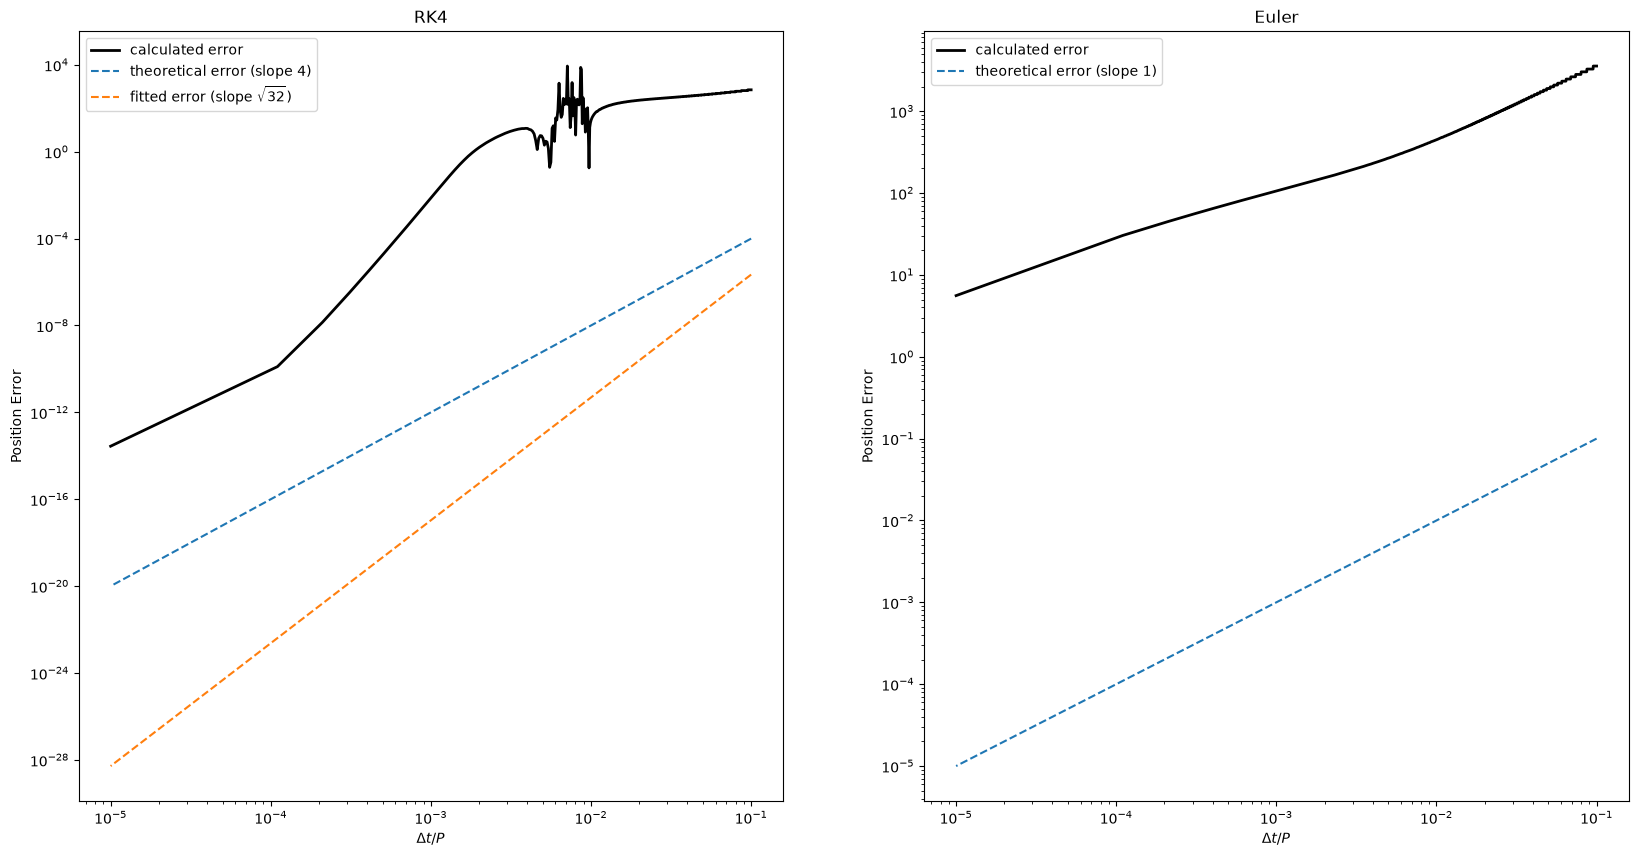

In [9]:
P = twobody.orbital_period(AU)
rk4_steps = np.linspace(P/10, P/1e5, 1000)
rk4_error = []
euler_steps = np.linspace(P/10, P/1e5, 1000)
euler_error = []

for i in range(1000):
    full_orbit_rk4 = integrators.integrate(integrators.rk4_step, twobody.kepler_derivs, twobody.initial_conditions(AU, e=0.9), (0, P), rk4_steps[i])
    position_rk4 = np.sqrt(full_orbit_rk4[1].T[0]**2 + full_orbit_rk4[1].T[1]**2)
    rk4_error.append(np.abs(position_rk4[0]-position_rk4[-1])/position_rk4[0])

    full_orbit_euler = integrators.integrate(integrators.euler_step, twobody.kepler_derivs, twobody.initial_conditions(AU, e=0.9), (0, P), euler_steps[i])
    position_euler = np.sqrt(full_orbit_euler[1].T[0]**2 + full_orbit_euler[1].T[1]**2)
    euler_error.append(np.abs(position_euler[0]-position_euler[-1])/position_euler[0])

fig, ax = plt.subplots(1, 2, figsize = (20, 10))

ax[0].loglog(rk4_steps/P, rk4_error, color = 'black', linewidth = 2, label = r'calculated error')
ax[0].loglog(rk4_steps/P, (rk4_steps/P)**4, '--', label = r'theoretical error (slope 4)')
ax[0].loglog(rk4_steps/P, (rk4_steps/P)**np.sqrt(32), '--', label = r'fitted error (slope $\sqrt{32}$)')

ax[1].loglog(euler_steps/P, euler_error, color = 'black', linewidth = 2, label = r'calculated error')
ax[1].loglog(euler_steps/P, euler_steps/P, '--', label = r'theoretical error (slope 1)')

ax[0].set_ylabel('Position Error')
ax[0].set_xlabel(r'$\Delta t/P$')
ax[0].set_title('RK4')
ax[0].legend()

ax[1].set_ylabel('Position Error')
ax[1].set_xlabel(r'$\Delta t/P$')
ax[1].set_title('Euler')
ax[1].legend()

The error increases significantly with a higher eccentricity! So much so that at the larger time steps RK4 and Euler have similar errors and decrease at similar rates. With RK4 I can see that at around $\Delta t/P$ = $10^{-4}$, the error starts to follow the theoretical slope of 4. It seems that the accuracy of an eccentric orbit is more limited to step size than a circular orbit. This makes sense though, thinking about the morphology of an eccentric orbit, because their elongated shape makes it that small deviations compound significantly (especially at perhielion and aphelion!) while a circular orbit much more forgiving.

### Part (d)
The energy drift per orbit for RK4 is $5.47 \times 10^{-11}$ (3 s.f.) so it would take 18,300,000 orbits (3 s.f.) to reach a drift of $10^{-3}$. This assumes that the drift increases linearly per orbit, which is very much supported by my plot in part (c) as it is linear. Though we are extrapolating, the Euler method shows much larger drifts per orbit and the behavior is still linear, so it is a valid assumption

### Part (e)
The RK4 would cross the $10^{-6}$ Leapfrog energy drift bound at orbit 18,282. As the time step tends towards zero, the solution tends towards the analaytical solution and hence tends towards zero loss of energy. So, as we reduce the time step, we reduce the total amount of energy lost per orbit but it will still add up linearly over time (reduces the slope of the linear increase). Since there is an increase regardless of the time step, we will eventually cross the Leapfrog bound.

## 4. The Hill radius and the edge of a satellite system

### Part (a)

In [30]:
import pandas as pd

data_planet = pd.read_csv('~/Desktop/astr5820/data/planet_elements.csv')
for i, name in enumerate(data_planet["name"]):
    print("The Hill Radius for {} is {:.2e} m = {:.2e} AU.".format(name, twobody.hill_radius(data_planet["a_au"][i]*AU, data_planet["mass_kg"][i]), twobody.hill_radius(data_planet["a_au"][i]*AU, data_planet["mass_kg"][i])/AU))
    if name == 'Earth':
        print("                               (this matches problem 1)")

The Hill Radius for Mercury is 2.21e+08 m = 1.48e-03 AU.
The Hill Radius for Venus is 1.01e+09 m = 6.76e-03 AU.
The Hill Radius for Earth is 1.50e+09 m = 1.00e-02 AU.
                               (this matches problem 1)
The Hill Radius for Mars is 1.08e+09 m = 7.25e-03 AU.
The Hill Radius for Jupiter is 5.31e+10 m = 3.55e-01 AU.
The Hill Radius for Saturn is 6.52e+10 m = 4.36e-01 AU.
The Hill Radius for Uranus is 7.01e+10 m = 4.68e-01 AU.
The Hill Radius for Neptune is 1.16e+11 m = 7.76e-01 AU.


### Part (b)

Kepler's third law is

$$P_{\text{satellite}}^2 = \frac{4 \pi^2 a_{\text{satellite}}^3}{G(m_{\text{planet}}+m_{\text{satellite}})} \approx \frac{4 \pi^2 a_{\text{satellite}}^3}{Gm_{\text{planet}}}$$

If we plug in $a_{\text{satellite}} = r_H = a_{\text{planet}}(\frac{m_{\text{planet}}}{3m_{\text{star}}})^{(1/3)} \implies a_{\text{satellite}}^3 = a_{\text{planet}}^3\frac{m_{\text{planet}}}{3m_{\text{star}}}$ we get:

$$P_{\text{satellite}}^2 = \frac{4 \pi^2}{Gm_{\text{planet}}}a_{\text{planet}}^3\frac{m_{\text{planet}}}{3m_{\text{star}}} = \frac{4 \pi^2}{Gm_{\text{star}}}a_{\text{planet}}^3\frac{1}{3} =\frac{1}{3} P_{\text{planet}}^2 \implies P_{\text{satellite}} = \frac{1}{\sqrt{3}} P_{\text{planet}}$$

as required.

For $a_{\text{satellite}} = 0.5r_H$, that will become a factor of $2^{-3/2}$ and $P_{\text{satellite}} = \frac{1}{\sqrt{3\times 2^3}} P_{\text{planet}} = \frac{1}{\sqrt{24}} P_{\text{planet}}$

### Part (c)

In [88]:
data_satellite = pd.read_csv('~/Desktop/astr5820/data/satellites.csv')

table_prograde = {}
table_retrograde = {}

for i, satellite in enumerate(data_satellite["name"]):
    planet = data_satellite["planet"][i]

    if data_satellite["direction"][i] == 'prograde':
        table = table_prograde
    else:
        table = table_retrograde
        
    if planet not in table.keys():
        table[planet] = []

    data_loc = np.where(data_planet["name"] == planet)[0][0]
    r_H = twobody.hill_radius(data_planet["a_au"][data_loc]*AU, data_planet["mass_kg"][data_loc])
    table[planet].append((data_satellite["a_m"][i]/r_H, satellite))


print("Prograde Satellites:")
print("---------------------")
for planet in table_prograde.keys():
    table_prograde[planet] = sorted(table_prograde[planet])[::-1] 
    print()
    print("{}: Name: {}, a/r_H = {:.2e}".format(planet, table_prograde[planet][0][1], table_prograde[planet][0][0]))
    print("-------")
print()
print("Retrograde Satellites:")
print("----------------------")
for planet in table_retrograde.keys():
    table_retrograde[planet] = sorted(table_retrograde[planet])[::-1] 
    print()
    print("{}: Name: {}, a/r_H = {:.2e}".format(planet, table_retrograde[planet][0][1], table_retrograde[planet][0][0]))
    print("-------")

Prograde Satellites:
---------------------

Jupiter: Name: Valetudo, a/r_H = 3.52e-01
-------

Saturn: Name: S/2004_S_24, a/r_H = 3.58e-01
-------

Uranus: Name: Margaret, a/r_H = 2.06e-01
-------

Neptune: Name: Laomedeia, a/r_H = 2.03e-01
-------

Retrograde Satellites:
----------------------

Jupiter: Name: Kore, a/r_H = 4.55e-01
-------

Saturn: Name: S/2020_S_44, a/r_H = 4.18e-01
-------

Uranus: Name: Ferdinand, a/r_H = 2.91e-01
-------

Neptune: Name: S/2021_N_1, a/r_H = 4.37e-01
-------


### Part (d)

In [ ]:
index = np.where(data_planet["name"] == "Saturn")[0][0]
Saturn_mass = data_planet["mass_kg"][index]
Saturn_radius = data_planet["radius_m"][index]
Saturn_density = Saturn_mass/(4/3 * np.pi * Saturn_radius**3)
d = 1.368*1e8
density_rigid = Saturn_density/(d/(1.44*Saturn_radius))**3
density_fluid = Saturn_density/(d/(2.44*Saturn_radius))**3

print("The mean density that rigid criterion requires in order to place the disruption boundary at the outer edge of Saturn’s A ring is {} kg/m^3.".format(density_rigid))
print("The mean density that fluid criterion requires in order to place the disruption boundary at the outer edge of Saturn’s A ring is {} kg/m^3.".format(density_fluid))

The mean density that rigid criterion requires in order to place the disruption boundary at the outer edge of Saturn’s A ring is 158.25185074823938 kg/m^3
The mean density that fluid criterion requires in order to place the disruption boundary at the outer edge of Saturn’s A ring is 769.8937614601791 kg/m^3


The density that is the closest to the density of ice is the one we get from the fluid criterion. That means that ring material is not very strong and almost behaves as a fluid.

### Part (e)

For prograde satellites, the largest $\frac{a}{r_H}$ ratio is 0.358 for S/2004_S_24 around Saturn and for retrograde satellites, the largest $\frac{a}{r_H}$ ratio is 0.455 for Kore around Jupiter. So the limits seem to differ with retrograde orbits being able to stay a little further away from the planet. From part (b) we know that a satellite at $r_H$ only does ~1.7 orbits around its host planet as the planet does a full rotation around the sun. Over the age of the solar system, such a satellite is essentially completing the same number of orbits around the sun as its planet, making it marginally bound.